# Simulation-based sample size determination

Simulation based sample size determination. 

From our hidden markov mode, we can now estimate $P(O=1|Y)$, where $Y$ is a series of $\text{CO}_2$ observations and $O$ is the occupancy. \\
\bigskip 

We can then estimate the proberbility 

$$
\hat{p} = \frac{\text{Number of complaints}}{\text{Expected number of occupied states}} = \frac{N}{\sum_t^{T} P(O_t = 1|y_{1:t
})}
$$

where $N$ should get us a 95% confidence intecal.
\bigskip 

This also assumes that 

$$
\hat{p} \sim \mathcal{N}(p, \sigma_p)
$$

Prediction Interval: 

$$
\text{MEAN}[\hat{p}] + t(R-1)\hat{\sigma} \sqrt{1 + \frac{1}{ R}}
$$

In [1]:
import jax
jax.config.update("jax_enable_x64", True)

from drivers.models.utils import fit_path, room_name
from drivers.utils import load_model
from src.api.v5 import Params
import jax.numpy as jnp



ROOM_NAME = 9
STATES = 5
MODEL_NAME = "ar1_hmm_beta_1"

saved = load_model(fit_path(room_name(ROOM_NAME), STATES, MODEL_NAME))
results = saved["result"]
model = results.params

In [2]:
from typing import Callable


class DataGenerater: 
    def __init__(self, feedback_prob: float, occupied_states: tuple[int, ...] | None = None): 
        self.gammas = None 
        self.mu_vals = None 
        self.std_vals = None 
        self.emission_list = [] 
        self.path = []
        self.key = None #jax.random.PRNGKey(key)
        self.sub_key = None
        self.num_states = None
        self.phi_vals = None
        self.params = None
        self.xs_fn = None
        self.feedback_prob = feedback_prob
        self.occupied_states = occupied_states  # None -> the last (highest-mu) state
        self.feedback_list = []
    


    def set_new_keys(self) -> None: 
        self.key, self.sub_key = jax.random.split(self.key) #type: ignore

    def generate_emissions(self, key: int, params: Params, u00: jax.Array, N: int,
                           xs_fn: Callable[[int], jax.Array] | None = None, max_steps: int = 100_000): 
        """Simulate until N feedback complaints have been drawn. Returns (emissions, path, feedbacks), all of equal length."""
        self.reset()
        self.key = jax.random.PRNGKey(key)
        self.params, self.xs_fn = params, xs_fn
        self.set_tranisition_matrix(7 * 48) 
        self.set_std_vals(params)
        self.set_mu_vals(params)  
        self.set_phi_vals(params)

        s0 = self.chose_state_0(u00.flatten())
        st = s0
        self.add_state_to_path(s0)

        y0 = self.get_first_emission(s0) 
        self.add_emission(y0)
        n_feedback = self.add_feedback(st)

        i = 0
        while n_feedback < N: 
            if i >= max_steps: 
                raise RuntimeError(f"Only {n_feedback}/{N} complaints after {max_steps} steps")
            st = self.get_next_state(i, st)
            yt = self.draw_emission(st, i)
            self.add_state_to_path(st) 
            self.add_emission(yt)
            n_feedback += self.add_feedback(st)
            i += 1

        emissions = jnp.asarray(self.emission_list)
        paths = jnp.asarray(self.path)
        feedbacks = jnp.asarray(self.feedback_list)
        self.reset()
        return emissions, paths, feedbacks

    def reset(self) -> None: 
        self.emission_list = []
        self.path = []
        self.feedback_list = []

    def set_tranisition_matrix(self, T: int) -> None: 
        xs = None if self.xs_fn is None else self.xs_fn(T)
        self.gammas = self.params.transition.transition_matrices(N = T, xs=xs) #type: ignore

    def set_std_vals(self, params: Params) -> None: 
        self.std_vals = params.emission.sigma(t=0, ys=0) 
    def set_mu_vals(self, params: Params) -> None: 
        self.mu_vals = params.emission.mu_vals(t=0, ys=0) 
    def set_phi_vals(self, params: Params) -> None: 
        self.phi_vals = params.emission.phi()

    def chose_state_0(self, u00: jax.Array) -> jax.Array: 
        self.num_states = len(u00)
        if self.occupied_states is None: 
            self.occupied_states = (self.num_states - 1,)
        self.set_new_keys()
        s0 = jax.random.choice(self.sub_key, self.num_states, p=u00) #type: ignore
        return s0 
    
    def add_state_to_path(self, st: jax.Array) -> None:
        self.path.append(st)

    def add_feedback(self, st: jax.Array) -> int: 
        f = self.draw_feedback(st)
        self.feedback_list.append(f)
        return f

    def draw_feedback(self, st: jax.Array) -> int: 
        if int(st) not in self.occupied_states: #type: ignore
            return 0
        self.set_new_keys()
        return int(jax.random.bernoulli(self.sub_key, self.feedback_prob)) #type: ignore

    def get_first_emission(self, s0: jax.Array) -> jax.Array: 
        s0 = jnp.int16(s0)  
        z = self.draw_standard_normal() 

        y0 = self.mu_vals[s0] + z*self.std_vals[s0]
        return y0

    def draw_standard_normal(self) -> jax.Array: 
        self.set_new_keys()
        z = jax.random.normal(self.sub_key, shape=(1,)) #type: ignore 
        return z
    
    def add_emission(self, yt: jax.Array) -> None: 
        self.emission_list.append(yt)  

    def get_next_state(self, i, st): 
        if i >= len(self.gammas): #type: ignore
            self.set_tranisition_matrix(2 * len(self.gammas)) #type: ignore
        gamma = self.gammas[i, : , :] 
        ut = gamma[st, :]
        self.set_new_keys()
        st = jax.random.choice(self.sub_key, self.num_states, p=ut) #type: ignore
        return st 
    
    def draw_emission(self, st, i) -> jax.Array: 
        z = self.draw_standard_normal() 
        y_pre = self.emission_list[i] 
        ar = jnp.sum(self.phi_vals * (y_pre - self.mu_vals[None, :]), axis=0) 

        mu = self.mu_vals + ar 

        return mu[st] + self.std_vals[st]*z 
    





In [3]:
import pandas as pd
from drivers.models.utils import COVARIATE_COLS, covariates


def week_covariates(N: int, cols=COVARIATE_COLS, start: str = "2024-03-04") -> jax.Array:
    """(N, C) covariates for the β models: one ordinary Mon-Sun week (30 min steps, no holidays) stacked until N rows."""
    week = covariates(pd.date_range(start, periods=7 * 48, freq="30min"), cols)
    return jnp.tile(week, (N // len(week) + 1, 1))[:N]

In [4]:
FEEDBACK_PROB = 0.05  # P(complaint | occupied state)
generator = DataGenerater(FEEDBACK_PROB)


In [5]:
N = 30  # number of feedback complaints to simulate until

u00 = jnp.ones(shape=(STATES,)) * (1/STATES)

In [6]:
#emissions, path, feedbacks = generator.generate_emissions(key=0, params=model, u00=u00, N=N, xs_fn=week_covariates)

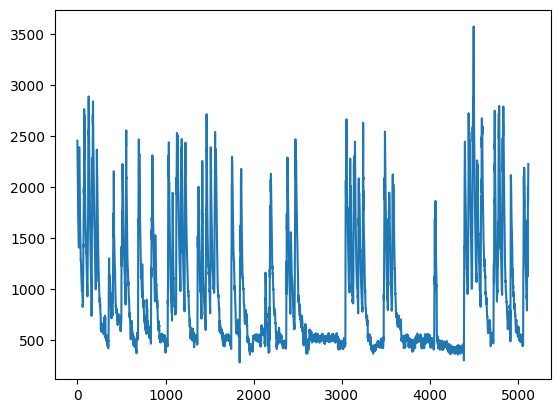

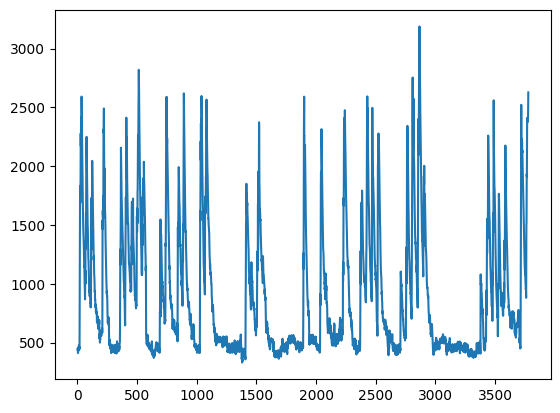

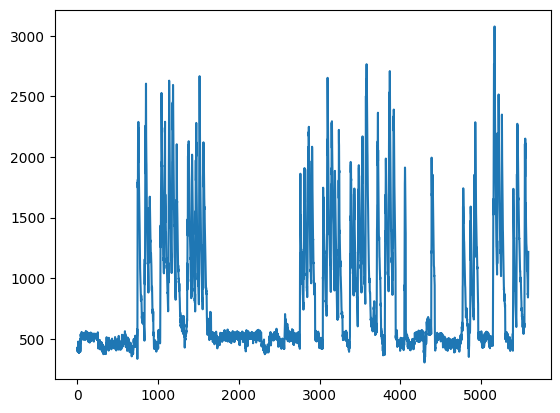

In [7]:
import matplotlib.pyplot as plt 

for i in range(3): 
    generator = DataGenerater(FEEDBACK_PROB)
    emissions, path, feedbacks = generator.generate_emissions(key=i, params=model, u00=u00, N=N, xs_fn=week_covariates)
    plt.plot(emissions)
    plt.show()

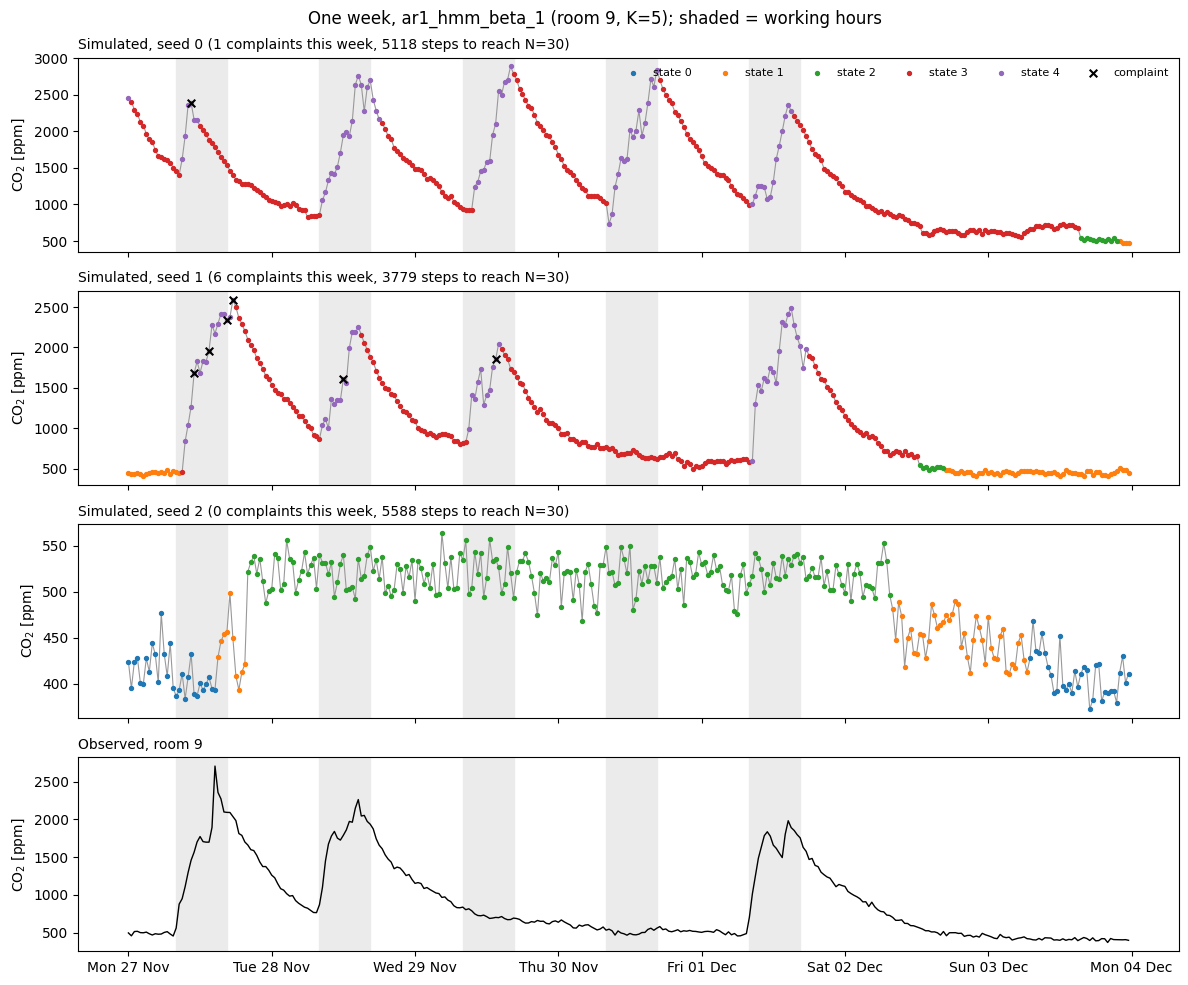

In [8]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

WEEK = 7 * 48
ROOM_WEEK = "2023-11-27"  # an ordinary Mon-Sun week in the training split; same weekday/time covariates as week_covariates

dt = pd.date_range(ROOM_WEEK, periods=WEEK, freq="30min")
work = np.asarray(week_covariates(WEEK)[:, COVARIATE_COLS.index("working_hours")]).astype(bool)
colors = plt.cm.tab10(np.arange(STATES))

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for i, ax in enumerate(axes[:3]):
    generator = DataGenerater(FEEDBACK_PROB)
    emissions, path, feedbacks = generator.generate_emissions(key=i, params=model, u00=u00, N=N, xs_fn=week_covariates)
    y, s, f = np.asarray(emissions).ravel()[:WEEK], np.asarray(path)[:WEEK], np.asarray(feedbacks)[:WEEK].astype(bool)
    dt_i = dt[:len(y)]  # a run can reach N complaints before a full week

    ax.plot(dt_i, y, color="0.6", lw=0.8)
    for k in range(STATES):
        ax.scatter(dt_i[s == k], y[s == k], color=colors[k], s=8, label=f"state {k}", zorder=3)
    ax.scatter(dt_i[f], y[f], marker="x", color="k", s=30, label="complaint", zorder=4)
    ax.set_title(f"Simulated, seed {i} ({int(f.sum())} complaints this week, {len(path)} steps to reach N={N})", loc="left", fontsize=10)

room = pd.Series(np.asarray(saved["data"].ys).ravel(), index=saved["data"].datetime).reindex(dt)
axes[3].plot(dt, room, color="k", lw=1)
axes[3].set_title(f"Observed, room {ROOM_NAME}", loc="left", fontsize=10)

for ax in axes:
    ax.fill_between(dt, 0, 1, where=work, transform=ax.get_xaxis_transform(), color="0.92", step="post", zorder=0)
    ax.set_ylabel("CO$_2$ [ppm]")
axes[0].legend(ncol=STATES + 1, loc="upper right", fontsize=8, frameon=False)
axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
fig.suptitle(f"One week, {MODEL_NAME} (room {ROOM_NAME}, K={STATES}); shaded = working hours")
fig.tight_layout()
plt.show()

In [9]:
#Now we get the oracle state and the emissions, now we try to compute the amount of feedback needed 
# In real life the true states are unknown: refit AR(1)-HMM(b,1) on the simulated CO2 and use
# the filtered P(O_t = 1 | y_{1:t}) of the occupied state as the denominator
from src.api.v5 import ForwardAlgorithm, LBFGSSolver

ys_sim = emissions.ravel()
xs_sim = week_covariates(len(ys_sim))
init_dist = jnp.ones((1, STATES)) / STATES
cfg = saved["config"]  # same loss (beta ridge) and tolerance as the driver

refit = LBFGSSolver(n_iter=cfg.n_iter, tol=cfg.tol).fit(params=model, loss_fn=cfg.loss.fn, data=(ys_sim, xs_sim, init_dist))
utt, _, _ = ForwardAlgorithm.run(params=refit.params, initial_dist=init_dist, ys=ys_sim, xs=xs_sim)

expected_occupied = utt[:, 0, jnp.asarray(generator.occupied_states)].sum()  # sum_t P(O_t = 1 | y_{1:t})
p_hat = feedbacks.sum() / expected_occupied

assert feedbacks.sum() == N and len(feedbacks) == len(path) == len(emissions)
print(f"refit converged: {refit.converged}, steps simulated: {len(path)}, complaints: {int(feedbacks.sum())}")
print(f"expected occupied steps: {float(expected_occupied):.1f}")
print(f"p_hat = {float(p_hat):.4f}  (true p = {FEEDBACK_PROB})")

refit converged: True, steps simulated: 5588, complaints: 30
expected occupied steps: 633.6
p_hat = 0.0473  (true p = 0.05)


## 95% interval for $\hat{p}$ as a function of $N$

Simulate $R$ datasets, each until $N_{\max}$ complaints, and refit AR(1)-HMM(b,1) on all of them at once (the L-BFGS loop is `vmap`ped over the datasets; they are padded to a common length and the padded steps are masked out of the likelihood). Since $P(O_t=1|y_{1:t})$ only uses data up to $t$, the cumulative sum of the filtered probabilities gives the denominator after the $n$-th complaint, so one dataset gives $\hat{p}$ for every $N = 1, \dots, N_{\max}$. The 2.5% and 97.5% percentiles across the $R$ datasets give the 95% interval, and $N$ is the smallest number of complaints where it is narrower than `TARGET_WIDTH`.

In [ ]:
import equinox as eqx
import optax.tree_utils as otu
from src.api.v5.solvers.base_solver import BaseSolver
from src.api.v5.solvers.freezer import Freezer

N_MAX = 10          # simulate every dataset until this many complaints
R = 3               # number of simulated datasets
TARGET_WIDTH = 0.02  # full width of the 95% interval (±0.01 around p = 0.05)
OCCUPIED = jnp.asarray(generator.occupied_states)

# 1) simulate R datasets; each runs until N_MAX complaints, so they differ in length
sims = [DataGenerater(FEEDBACK_PROB).generate_emissions(key=k, params=model, u00=u00, N=N_MAX, xs_fn=week_covariates) for k in range(R)]
lengths = jnp.array([len(fb) for _, _, fb in sims])
T_max = int(lengths.max())

# 2) pad to a common length so they stack for vmap; padded steps are masked out of the loss
ys_b = jnp.stack([jnp.pad(em.ravel(), (0, T_max - len(em)), mode="edge") for em, _, _ in sims])  # (R, T_max)
mask_b = jnp.arange(T_max)[None, :] < lengths[:, None]                                         # (R, T_max)
complaint_times = jnp.stack([jnp.flatnonzero(fb) for _, _, fb in sims])                       # (R, N_MAX)
xs_all = week_covariates(T_max)
print(f"steps per dataset: min {int(lengths.min())}, max {T_max}")

In [ ]:
import time

N_ITER = 5_000  # vmapped while-loop runs until *every* dataset stops, so cap it instead of cfg.n_iter = 100_000

def masked_loss(params: Params, data) -> jax.Array:
    """Driver loss (NLL + ridge) with the padded steps left out of the NLL."""
    ys, mask = data
    _, f_t, _ = ForwardAlgorithm.run(params=params, initial_dist=init_dist, ys=ys, xs=xs_all)
    loss = -jnp.sum(jnp.where(mask, jnp.log(f_t), 0.0))
    loss = loss + cfg.loss.beta_lam * jnp.sum(params.transition.beta ** 2)
    return loss + cfg.loss.sigma_lam * jnp.sum(jnp.exp(params.emission.log_sigma) ** 2)

# 3) refit all R datasets at once by vmapping the solver's jitted L-BFGS while-loop over the data
solver = LBFGSSolver(n_iter=N_ITER, tol=cfg.tol)
freezer = Freezer(None)
trainable, static = eqx.partition(model, freezer.filter_spec(model))
objective = BaseSolver._objective(masked_loss, static, freezer, model)

t0 = time.time()
trainable_b, state_b = jax.vmap(lambda ys, mask: solver._run(objective, trainable, (ys, mask)))(ys_b, mask_b)
trainable_b = jax.block_until_ready(trainable_b)
grad_norm = jnp.sqrt(sum(jnp.sum(g.reshape(R, -1) ** 2, axis=1) for g in jax.tree_util.tree_leaves(otu.tree_get(state_b, "grad"))))
print(f"refit {R} datasets in {time.time() - t0:.0f} s, converged (grad norm < {cfg.tol}): {int(jnp.sum(grad_norm < cfg.tol))}/{R}")
print("grad norm per dataset:", np.round(np.asarray(grad_norm), 6))

In [ ]:
# 4) filtered P(occupied) per dataset -> p_hat after the n-th complaint, for n = 1..N_MAX
def p_hat_curve(trainable_i, ys, t_n) -> jax.Array:
    params = eqx.combine(trainable_i, static)
    utt, _, _ = ForwardAlgorithm.run(params=params, initial_dist=init_dist, ys=ys, xs=xs_all)
    expected_occupied = jnp.cumsum(utt[:, 0, OCCUPIED].sum(axis=-1))  # sum_{s<=t} P(O_s = 1 | y_{1:s})
    return jnp.arange(1, N_MAX + 1) / expected_occupied[t_n]

curves = jax.vmap(p_hat_curve)(trainable_b, ys_b, complaint_times)  # (R, N_MAX)

# 5) 95% interval across the R datasets, and the smallest N where it is narrow enough
Ns = np.arange(1, N_MAX + 1)
lo, hi = np.percentile(np.asarray(curves), [2.5, 97.5], axis=0)
narrow = (hi - lo) <= TARGET_WIDTH
N_needed = int(Ns[np.argmax(narrow)]) if narrow.any() else None
half_width = 1.96 * FEEDBACK_PROB * np.sqrt((1 - FEEDBACK_PROB) / Ns)  # known-states approximation

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(Ns, np.asarray(curves).T, color="0.75", lw=0.6)
ax.fill_between(Ns, lo, hi, color="tab:blue", alpha=0.3, label=f"95% interval ({R} simulations)")
ax.plot(Ns, FEEDBACK_PROB - half_width, "k--", lw=1, label="95% interval, known states")
ax.plot(Ns, FEEDBACK_PROB + half_width, "k--", lw=1)
ax.axhline(FEEDBACK_PROB, color="tab:red", lw=1, label=f"true p = {FEEDBACK_PROB}")
if N_needed is not None:
    ax.axvline(N_needed, color="tab:green", lw=1, label=f"width ≤ {TARGET_WIDTH} at N = {N_needed}")
ax.set_xlabel("N, number of complaints")
ax.set_ylabel(r"$\hat{p}$")
ax.set_ylim(0, 3 * FEEDBACK_PROB)
ax.legend(frameon=False)
ax.set_title(f"{MODEL_NAME}, room {ROOM_NAME}, K={STATES}: p_hat refitted on simulated data", loc="left", fontsize=10)
plt.show()

for n in sorted({n for n in (10, 30, 50, 100) if n < N_MAX} | {N_MAX}):
    print(f"N = {n:3d}: 95% interval [{lo[n - 1]:.4f}, {hi[n - 1]:.4f}], width {hi[n - 1] - lo[n - 1]:.4f}")
print(f"smallest N with width <= {TARGET_WIDTH}: {N_needed}")